# Mini-project 1

**Machine Learning for Public Policy**

Jay Ballesteros

October 15, 2026

In [48]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels .api as sm
import statsmodels.formula.api as smf
from statsmodels .stats. outliers_influence \
import variance_inflation_factor as VIF
from statsmodels .stats.anova import anova_lm
from pygam import LinearGAM, s, te

pd.set_option('display.max_columns', None)


## Preparing the data

In [13]:
acs_data = pd.read_csv("/Users/jballesteros/Documents/git/uchicago-mpp/4_autumn_2026/machine_learning/project_1/_data/usa_00001.csv")
acs_data.columns = acs_data.columns.str.lower()

In [14]:
acs_data.head()

,year,sample,serial,cbserial,hhwt,cluster,strata,gq,pernum,perwt,nchild,sex,age,marst,race,raced,hispan,hispand,educ,educd,empstat,empstatd,incwage,vetstat,vetstatd
0,2024,202401,3875,2024000005657,9955.2,2024000038751,120101,1,1,9955.2,0,2,60,1,1,177,0,0,6,63,1,10,50000,1,11
1,2024,202401,4201,2024000028495,1468.8,2024000042011,50101,1,1,1468.8,3,1,37,1,1,177,0,0,8,81,1,10,47800,1,11
2,2024,202401,4691,2024000060600,12566.4,2024000046911,50101,1,1,12566.4,0,1,66,1,1,177,0,0,6,64,1,10,18700,1,11
3,2024,202401,4691,2024000060600,12566.4,2024000046911,50101,1,2,12566.4,0,2,61,1,6,600,0,0,8,81,1,10,58000,1,11
4,2024,202401,4854,2024000071420,3264.0,2024000048541,230001,1,1,3427.2,1,1,53,3,1,117,0,0,6,64,1,10,110000,1,11


### 2.
#### (a)

Education - We have a categorical measurement of education (educd). For some of our
analysis, we need a continuous variable. Use the educd variable to create a continuous
measure of education called educdc using the crosswalk at the end of this document.
A *.csv version of the crosswalk is available on Canvas.

In [15]:
crosswalk = pd.read_csv('/Users/jballesteros/Documents/git/uchicago-mpp/4_autumn_2026/machine_learning/project_1/_data/PPHA_30545_MP01-Crosswalk.csv')

In [18]:
acs_data = acs_data.merge(crosswalk, on='educd')

#### (b)

Indicator Variables - Create the following indicator variables:

In [21]:
acs_data.columns

Index(['year', 'sample', 'serial', 'cbserial', 'hhwt', 'cluster', 'strata',
       'gq', 'pernum', 'perwt', 'nchild', 'sex', 'age', 'marst', 'race',
       'raced', 'hispan', 'hispand', 'educ', 'educd', 'empstat', 'empstatd',
       'incwage', 'vetstat', 'vetstatd', 'educdc'],
      dtype='object')

In [25]:
acs_data['educd'].unique()


array([ 63,  81,  64, 114, 101,  71,  61,  50,  65,  40, 116,  23, 115,
         2,  22,  26,  11,  15,  17,  30,  16,  25,  14,  12])

i. An indicator, hsdip, equal to 1 if the individual has a high school diploma (but not
a bachelors or higher degree).

In [26]:
acs_data['hsdip'] = np.where(
    (acs_data['educd'] >= 62) & (acs_data['educd'] < 101),
    1,
    0
)

In [27]:
# Sanity check: should print 4835 on the full 9,388-row sample
print(acs_data['hsdip'].sum())

4835


ii. An indicator, coldip, equal to 1 if the individual has a four-year college diploma
(i.e, a bachelor’s or a higher degree that required earning a college diploma first).

In [28]:
acs_data['coldip'] = np.where(
    (acs_data['educd'] >= 101) & (acs_data['educd'] <= 116),
    1,
    0
)

iii. An indicator, white, equal to 1 if the individual is white.

iv. An indicator, black, equal to 1 if the individual is black.

In [29]:
acs_data['white'] = np.where(acs_data['race'] == 1, 1, 0)
acs_data['black'] = np.where(acs_data['race'] == 2, 1, 0)

v. An indicator, hispanic, equal to 1 if the individual is of Hispanic origin.

In [30]:
acs_data['hispanic'] = np.where(
    (acs_data['hispan'] >= 1) & (acs_data['hispan'] <= 4),
    1,
    0
)

vi. An indicator, married, equal to 1 if the individual is married.

In [33]:
acs_data['married'] = np.where(
    (acs_data['marst'] == 1) | (acs_data['marst'] == 2),
    1,
    0
)

vii. An indicator, f emale, equal to 1 if the individual is female.

In [34]:
acs_data['female'] = np.where(acs_data['sex'] == 2, 1, 0)


viii. An indicator, vet, equal to 1 if the individual is a veteran

In [35]:
acs_data['vet'] = np.where(acs_data['vetstat'] == 2, 1, 0)

#### (c) 
Interaction Terms - Create an interaction between each of the education indicator vari-
ables (hsdip and coldip) and the continuous measure of education (educdc).

In [36]:
acs_data['hsdip_educdc'] = acs_data['hsdip'] * acs_data['educdc']
acs_data['coldip_educdc'] = acs_data['coldip'] * acs_data['educdc']

#### (d) 
Created Variables - Create the following

i. Age squared.
ii. The natural log of incwage.

In [37]:
acs_data['agesq'] = np.power(acs_data['age'], 2)

In [38]:
acs_data = acs_data[acs_data['incwage'] > 0].copy()
acs_data['lnincwage'] = np.log(acs_data['incwage'])

## Data Analysis

### 1. 
Compute descriptive (summary) statistics for the following variables: year, incwage, lnincwage, educdc, f emale, age, age2, white, black, hispanic, married, nchild, vet, hsdip, coldip, and the interaction terms. In other words, compute sample means, standard deviations, etc. Be sure to use this (and other) exploratory data analysis (EDA) techniques to sanity check your data. For instance, since we restricted the sample to people ages 14 to 70, you could check that the minimum and maximum values of the age variable are consistent with this restriction.

In [41]:
summary_vars = [
    'year', 'incwage', 'lnincwage', 'educdc', 'female', 'age', 'agesq',
    'white', 'black', 'hispanic', 'married', 'nchild', 'vet',
    'hsdip', 'coldip', 'hsdip_educdc', 'coldip_educdc'
]

acs_data[summary_vars].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
year,8909.0,2024.00,0.00,2024.00,2024.00,2024.00,2024.0,2024.00
incwage,8909.0,72611.84,85574.52,40.00,28000.00,51000.00,89000.0,907000.00
lnincwage,8909.0,10.69,1.14,3.69,10.24,10.84,11.4,13.72
educdc,8909.0,14.27,3.06,0.00,12.00,14.00,16.0,22.00
female,8909.0,0.48,0.50,0.00,0.00,0.00,1.0,1.00
age,8909.0,42.47,14.29,16.00,31.00,42.00,54.0,70.00
agesq,8909.0,2007.57,1233.73,256.00,961.00,1764.00,2916.0,4900.00
white,8909.0,0.67,0.47,0.00,0.00,1.00,1.0,1.00
black,8909.0,0.08,0.27,0.00,0.00,0.00,0.0,1.00
hispanic,8909.0,0.16,0.37,0.00,0.00,0.00,0.0,1.00


### 2. 
Scatter plot ln(incwage) and education (the continuous measure). Include a linear fit line. Be sure to label all axes and include an informative title.

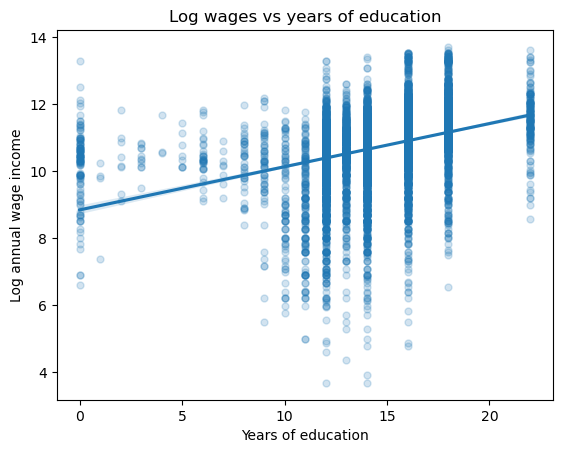

In [51]:
ax = sns.regplot(
    x='educdc', y='lnincwage', data=acs_data,
    scatter_kws={'alpha': 0.2, 's': 25}
)
ax.set_xlabel('Years of education')
ax.set_ylabel('Log annual wage income')
ax.set_title('Log wages vs years of education')
plt.show()

### 3
Estimate the following model: ln(incwage) = β0 + β1educdc + β2 f emale + β3age + β4age2 + β5white + β6black + β7hispanic + β8married + β9nchild + β10vet+ ε, 

In [63]:
result = smf.ols('lnincwage ~ educdc + female + age + agesq + white + black + hispanic + married + nchild + vet', data = acs_data).fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:              lnincwage   R-squared:                       0.321
Model:                            OLS   Adj. R-squared:                  0.320
Method:                 Least Squares   F-statistic:                     420.2
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:15:33   Log-Likelihood:                -12064.
No. Observations:                8909   AIC:                         2.415e+04
Df Residuals:                    8898   BIC:                         2.423e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      5.8000      0.104     55.841      0.0

#### (a)
**What fraction of the variation in log wages does the model explain?**

R: According to the R-squared of the model, explains about 32.1% of the variation in log wages.

#### (b)
**What is the return to an additional year of education? Is this statistically significant? Is it practically significant? Briefly explain.**

R: For each additional year of education, all else equal, we get a 0.1044 log points wage increase (11% wage increase%). It' statistically significant, because $p$ is virtually 0! Practically significant, yes. Considering a median wage of 51k, for each additional year of education, increase will give the median 5.6k. It is meaningfull because compounding each additional year, someone will get more a great net increase. Nonetheless we still don't know when that increase becomes marginal.

In [57]:
pct_return = (np.exp(result.params['educdc']) - 1) * 100
pct_return

np.float64(11.00856103925687)

#### (c)
**At what age does the model predict an individual will achieve the highest wage?**

R: At 48.1 years old

In [65]:
-result.params['age'] / (2 * result.params['agesq'])

np.float64(48.05561259163142)

#### (d)

**Does the model predict that men or women will have higher wages, all else equal? Briefly explain why we might observe this pattern in the data.**

R: The model predicts that, all else equal, men will have higher wages. Females, on average, have -31.17% in wages compared to men ( -0.3736 log points). It is statistically significant at $p$ < 0.001.

In [64]:
(np.exp(result.params['female']) - 1) * 100

np.float64(-31.177957725289072)

#### (e)
**Interpret the coefficients on the white and black variables and their significance**
For white people we get -0.0687 log points relatite to the ommitted group. Nonetheless the results at not significant at $p$ < 5%. In the case of black people, the coefficient is -0.2849 compared the ommitted group. Results are significant at $p$ < 0.001.

### 4. 
Graph ln(incwage) and education. Include three distinct linear fit lines specific to individuals
with no high school diploma, a high school diploma, and a college degree. Be sure to label
all axes and include an informative title.

In [82]:
groups = {
    'No HS diploma': acs_data[(acs_data['hsdip'] == 0) & (acs_data['coldip'] == 0)],
    'HS diploma': acs_data[acs_data['hsdip'] == 1],
    'College degree': acs_data[acs_data['coldip'] == 1],
}

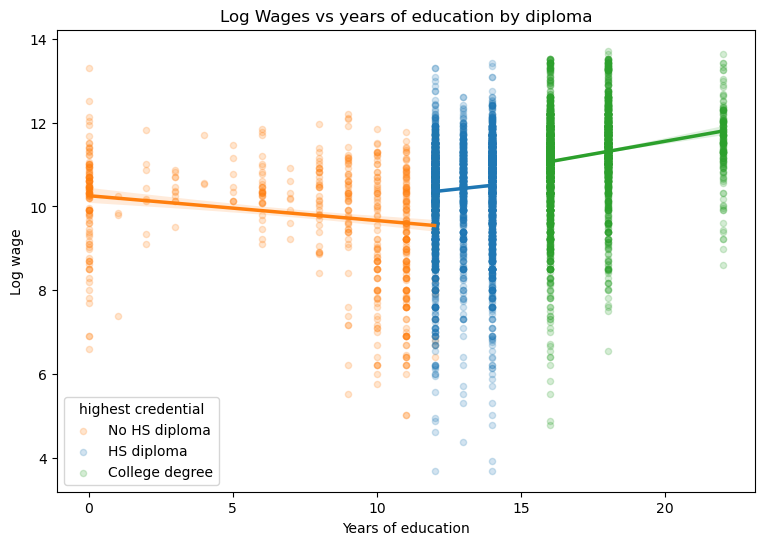

In [81]:
colors = {'No HS diploma': 'tab:orange', 'HS diploma': 'tab:blue', 'College degree': 'tab:green'}

fig, ax = plt.subplots(figsize=(9, 6))

for label, subset in groups.items():
    sns.regplot(
        x='educdc', y='lnincwage', data=subset, ax=ax,
        color=colors[label], label=label,
        scatter_kws={'alpha': 0.20, 's': 20},
        line_kws={'linewidth': 2.5}
    )

ax.set_xlabel('Years of education')
ax.set_ylabel('Log wage')
ax.set_title('Log Wages vs years of education by diploma')
ax.legend(title='highest credential')
plt.show()

### 5. 
The President asks you to determine a tool that can be used to predict wages for those considering a college degree so that future constituents can make informed decisions.

#### (a) 
Write down a differential intercept and/or differential slope model of log wages that will allow the returns to education to vary by degree acquired (use the three categories in the previous question).12 Be sure to include the controls from Question 3. Using theory, intuition, and/or common sense, explain justify why you think your model is the best possible representation of the way the world works (in other words, why you think you are correctly modeling f (X) but not over-fitting ε).


$$
\begin{aligned}
\ln(\text{incwage}_i) = {} & \beta_0 + \delta_1\,\text{hsdip}_i + \delta_2\,\text{coldip}_i + \beta_1\,\text{educdc}_i \\
& + \gamma_1(\text{hsdip}_i \times \text{educdc}_i) + \gamma_2(\text{coldip}_i \times \text{educdc}_i) \\
& + \beta_2\,\text{female}_i + \beta_3\,\text{age}_i + \beta_4\,\text{age}_i^2 + \beta_5\,\text{white}_i + \beta_6\,\text{black}_i \\
& + \beta_7\,\text{hispanic}_i + \beta_8\,\text{married}_i + \beta_9\,\text{nchild}_i + \beta_{10}\,\text{vet}_i + \varepsilon_i
\end{aligned}
$$

The base group is workers without a high school diploma. The return to one more year of education is:

- $\beta_1$ for workers with no HS diploma
- $\beta_1 + \gamma_1$ for HS graduates
- $\beta_1 + \gamma_2$ for college graduates

#### (b) 
Estimate the model you proposed in the previous question and report your results.

In [83]:
result_q5 = smf.ols(
    'lnincwage ~ hsdip + coldip + educdc + hsdip_educdc + coldip_educdc'
    ' + female + age + agesq + white + black + hispanic + married + nchild + vet',
    data=acs_data
).fit()
print(result_q5.summary())

                            OLS Regression Results                            
Dep. Variable:              lnincwage   R-squared:                       0.342
Model:                            OLS   Adj. R-squared:                  0.341
Method:                 Least Squares   F-statistic:                     329.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:23:11   Log-Likelihood:                -11924.
No. Observations:                8909   AIC:                         2.388e+04
Df Residuals:                    8894   BIC:                         2.399e+04
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         6.9541      0.127     54.622

#### (c)
Given your model estimates from the previous question, predict the wages of an 22 year old, female individual (who is neither white, black, nor Hispanic is not married, has no children, and is not a veteran) with a high school diploma and an all else equal individual with a college diploma. Assume that it takes someone 12 years to graduate high school and 16 years to graduate college.

In [84]:
people = pd.DataFrame({
    'hsdip':         [1, 0],
    'coldip':        [0, 1],
    'educdc':        [12, 16],
    'hsdip_educdc':  [12, 0],   # = hsdip * educdc
    'coldip_educdc': [0, 16],   # = coldip * educdc
    'female': 1, 'age': 22, 'agesq': 22**2,
    'white': 0, 'black': 0, 'hispanic': 0,
    'married': 0, 'nchild': 0, 'vet': 0
}, index=['HS diploma', 'College degree'])

people['pred_lnwage'] = result_q5.predict(people)
people['pred_wage'] = np.exp(people['pred_lnwage'])   # convert to dollars
people[['pred_lnwage', 'pred_wage']]

,pred_lnwage,pred_wage
HS diploma,9.478474,13075.219806
College degree,10.067834,23572.443804


**The President wants to know, given your results from the previous question, do indi-
viduals with college degrees have higher predicted wages than those without? By how
much? Briefly explain.**

- In dollars: 23,572 − 13,075 ≈ $10,500 more per year
- In percent: the log difference is 10.068 − 9.479 = 0.589, and e^0.589 − 1 ≈ 80% higher

the extra 4 years of education at the college slope, plus the sheepskin shift from the degree itself. Note that it’s a predicted, associational difference, not proof that college causes it

**The President gets excited by your results and is now considering legislation that will
expand access to college education (for instance, by increasing student loan subsidies).
Given the evidence provided by your model, would you advise the President to pursue
this legislation?**

No. This is a prediction model, not a causal one. Better to look for causal evidence, such as randomized or quasi-experimental studies of financial aid (e.g., lotteries or eligibility cutoffs), and weigh the costs, which the model doesn’t include.

**What fraction of the variation in log wages does the model explain? How does this
compare to the model you estimated in Question 3? Is it reasonable to compare these
two statistics? Briefly explain.**

The model explains about 34.2% of the variation in log wages, versus 32.1% in Q3, an increase of about 2 percentage points.

And partly. The two r-squared are comparable in one sense: both models use the same outcome (ln incwage) and the same sample (8,909 people)

**The President is concerned that citizens will be harmed (and voters unhappy) if the
predictions from your model turn out to be wrong. She wants to know how confident
you are in your predictions. Briefly explain.**

With 8,909 observations, the coefficients are precisely estimated (small standard errors), so the model’s prediction for the average 22-year-old woman with these characteristics is fairly reliable.

### 6

You remember that splines may be useful when generating predictions when you have non-
linear relationships, such as with age. You hypothesize that there may be an increase in
predictive power if we account for life milestones.

In [85]:
controls = ' + educdc + female + white + black + hispanic + married + nchild + vet'

**Estimate a model with a cubic spline in age and two knots: one at age 24 and another
at age 55. Keep the other relevant predictors in Question 3 in your model. Report the
adjusted R2
.**

In [86]:
m6a = smf.ols('lnincwage ~ bs(age, knots=(24, 55), degree=3)' + controls, data=acs_data).fit()
print('6a cubic (24, 55):', m6a.rsquared_adj) # 0.3404083027006888

6a cubic (24, 55): 0.3404083027006888


**Compare this adjusted R2 to the analog from the regression in Question 3. Why are
these different? Briefly explain.**

In [ ]:
Compare this adjusted R2 to the analog from the regression in Question 3. Why are
these different? Briefly explain.

**We used theory to motivate where we placed our knots. (Not very machine learning of
us.) To practice tuning model parameters (that are determined prior to fitting and affect
model flexibility), experiment by fitting three models: a cubic spline with knots at 18
and 65, a natural cubic spline with knots at 18 and 65, and another spline of your own
choosing. Report the adjusted R2 for each. Explain which model you prefer and why.**

The knots-at-30-and-45 spline has the highest adjusted r-squared, so it’s the preferred choice. Why 18 and 65 do worse? very few workers are younger than 18 or older than 65, so those knots spend the model’s flexibility on sparse tails. That leaves the dense middle of the age distribution, where most of the action is, fit by a single cubic. Knots at 30 and 45 put the flexibility where the data are.

In [88]:
m6c1 = smf.ols('lnincwage ~ bs(age, knots=(18, 65), degree=3)' + controls, data=acs_data).fit()

m6c2 = smf.ols("lnincwage ~ cr(age, knots=(18, 65), constraints='center')" + controls, data=acs_data).fit()

m6c3 = smf.ols('lnincwage ~ bs(age, knots=(30, 45), degree=3)' + controls, data=acs_data).fit()
print('cubic (18,65):', m6c1.rsquared_adj, '| natural (18,65):', m6c2.rsquared_adj, '| own:', m6c3.rsquared_adj)


cubic (18,65): 0.33341378279184086 | natural (18,65): 0.3287258329938836 | own: 0.34089227549614365


**Splines use our data differently than traditional, more-linear regressions. Using the
first model from Question 6c (the cubic spline with knots at 18 and 65), generate two
predicted values for a female individual (who is neither white, black, nor Hispanic,
is not married, has no children, and is not a veteran) with 12 years of education: one
prediction for the individual at age 17 and the other at age 50. Explain why these values
are different.**

Age 17: predicted log wage 8.67, or about $5,840 per year
Age 50: predicted log wage 10.55, or about $38,155 per year

They differ because they have different spline pieces. Age 17 falls below the first knot (18), so its prediction comes from the first cubic piece. Age 50 falls in the middle region (18–65).

In [89]:
people6 = pd.DataFrame({'age': [17, 50], 'educdc': 12, 'female': 1, 'white': 0, 'black': 0,
                        'hispanic': 0, 'married': 0, 'nchild': 0, 'vet': 0})
people6['pred_lnwage'] = m6c1.predict(people6)
people6['pred_wage'] = np.exp(people6['pred_lnwage'])
people6

,age,educdc,female,white,black,hispanic,married,nchild,vet,pred_lnwage,pred_wage
0,17,12,1,0,0,0,0,0,0,8.672451,5839.797918
1,50,12,1,0,0,0,0,0,0,10.549411,38154.954177
